# Exploración reproducible de vuelos BTS

Equipo: Diego García, Jose Miguel Guevara y Santiago Roldán.

**Datos de esta ejecución:** muestra regenerada de enero de 2025, 5,000 filas y 21 columnas; semilla 42. Esta muestra sirve para evaluar código y calidad. No sustituye el EDA de 24 meses del notebook original, conservado en `antecedentes/`.

Una fila representa un segmento de vuelo programado reportado por una aerolínea. El resultado es retraso de salida de puerta de 15 minutos o más, solo en vuelos operados con retraso conocido. El horizonte de tres horas es el objetivo; esta exploración no demuestra disponibilidad predictiva en tiempo real.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config/project.yaml').exists())
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.processing.contracts import KEY,hhmm_minutes,label_delay15
from src.validation.audit_sample import audit_frame
plt.rcParams.update({'figure.figsize':(10,4),'axes.grid':True,'grid.alpha':.2})
df = pd.read_csv(ROOT/'data/sample/flights_2025_01.csv')
provenance = json.loads((ROOT/'data/sample/flights_2025_01.provenance.json').read_text(encoding='utf-8'))
print('Dimensiones:',df.shape)
print('Origen:',provenance['source_url'])
print('Filas originales del mes:',provenance['original_rows'])
display(df.head())

Dimensiones: (5000, 21)
Origen: https://transtats.bts.gov/PREZIP/On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_1.zip
Filas originales del mes: 539747


,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Tail_Number,Origin,Dest,Distance,CRSDepTime,CRSArrTime,CRSElapsedTime,...,ArrTime,DepDelay,ArrDelay,Cancelled,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025-01-29,OO,6279,N705SK,ORD,BNA,409.0,1730,1900,90.0,...,1853.0,-3.0,-7.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
1,2025-01-13,AS,700,N713AL,SEA,PHX,1107.0,1259,1650,171.0,...,1628.0,-7.0,-22.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
2,2025-01-20,DL,2970,N370NB,MSP,DFW,852.0,1025,1310,165.0,...,1257.0,14.0,-13.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,2025-01-17,WN,1289,N8879Q,BWI,DAL,1209.0,845,1125,220.0,...,1115.0,18.0,-10.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
4,2025-01-18,G4,1808,279NV,ABE,SFB,882.0,700,944,164.0,...,934.0,-13.0,-10.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN


## Tipos, valores faltantes y duplicados

In [2]:
quality = pd.DataFrame({'tipo':df.dtypes.astype(str),'faltantes':df.isna().sum(),'porcentaje':df.isna().mean().mul(100).round(2)})
display(quality)
print('Duplicados completos:',df.duplicated().sum())
print('Duplicados en clave candidata:',df.duplicated(KEY).sum())
audit = audit_frame(df)
print('Auditoría aprobada:',audit['passed'])
display(pd.DataFrame(audit['checks']))

,tipo,faltantes,porcentaje
FlightDate,str,0,0.00
Reporting_Airline,str,0,0.00
Flight_Number_Reporting_Airline,int64,0,0.00
Tail_Number,str,26,0.52
Origin,str,0,0.00
Dest,str,0,0.00
Distance,float64,0,0.00
CRSDepTime,int64,0,0.00
CRSArrTime,int64,0,0.00
CRSElapsedTime,float64,0,0.00


Duplicados completos: 0
Duplicados en clave candidata: 0
Auditoría aprobada: True


,check,violations,passed
0,required_columns,0,True
1,valid_dates,0,True
2,required_keys,0,True
3,unique_natural_key,0,True
4,cancelled_binary,0,True
5,diverted_binary,0,True
6,scheduled_hhmm,0,True
7,distance_positive,0,True
8,origin_format,0,True
9,destination_format,0,True


Los campos de causas de retraso tienen nulos estructurales y no deben completarse con cero de forma automática. El notebook original registra 81.74% de nulos en esos campos para esta muestra. Tres cancelados tienen `DepDelay` reportado: aun así se excluyen de la etiqueta, conservándose en la capa limpia. Los resultados reales y las causas de retraso solo sirven para EDA o como objetivos; no son predictores del mismo vuelo a tres horas.

In [3]:
df['delay15'] = pd.Series([label_delay15(c,d) for c,d in zip(df.Cancelled,df.DepDelay)],dtype='Int8')
eligible = df[df.delay15.notna()].copy()
print('Cancelados:',df.Cancelled.eq(1).sum())
print('Cancelados con DepDelay reportado:',(df.Cancelled.eq(1)&df.DepDelay.notna()).sum())
print('Vuelos elegibles:',len(eligible))
print('Con retraso >=15 min:',eligible.delay15.sum())
print(f'Tasa de retraso: {eligible.delay15.mean():.2%}')
display(eligible[['DepDelay','ArrDelay','Distance','CRSElapsedTime']].describe(percentiles=[.5,.75,.9,.95,.99]).T)

Cancelados: 164
Cancelados con DepDelay reportado: 3
Vuelos elegibles: 4836
Con retraso >=15 min: 896
Tasa de retraso: 18.53%


,count,mean,std,min,50%,75%,90%,95%,99%,max
DepDelay,4836.0,11.092432,56.673885,-26.0,-3.0,6.00,40.0,75.00,213.65,1266.0
ArrDelay,4822.0,4.557238,59.414972,-56.0,-8.0,7.00,39.0,79.00,227.79,1279.0
Distance,4836.0,847.187552,591.304974,67.0,713.5,1087.50,1672.5,2154.25,2631.25,5095.0
CRSElapsedTime,4836.0,151.741108,73.077304,37.0,136.0,184.25,253.0,309.00,387.65,690.0


## Distribución y valores extremos

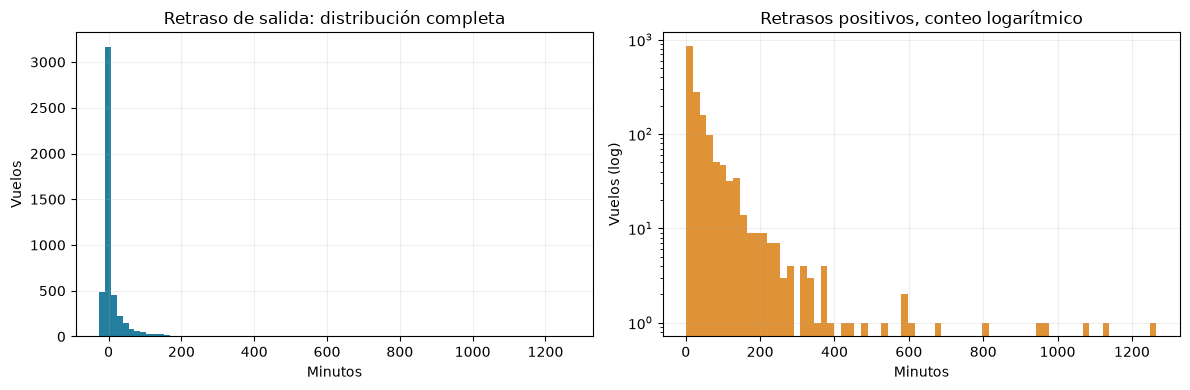

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].hist(eligible.DepDelay,bins=80,color='#247f9e')
axes[0].set(title='Retraso de salida: distribución completa',xlabel='Minutos',ylabel='Vuelos')
positive=eligible.loc[eligible.DepDelay.gt(0),'DepDelay']
axes[1].hist(positive,bins=70,color='#e09236')
axes[1].set_yscale('log')
axes[1].set(title='Retrasos positivos, conteo logarítmico',xlabel='Minutos',ylabel='Vuelos (log)')
fig.tight_layout()
figures=ROOT/'reports/figures';figures.mkdir(parents=True,exist_ok=True)
fig.savefig(figures/'sample_delay_distribution.png',dpi=160,bbox_inches='tight')
plt.show()

Las salidas adelantadas generan minutos negativos válidos. Los extremos no se eliminan por ser grandes: requieren revisión. Los ajustes exponencial/gamma/lognormal se estudiarían sobre los retrasos positivos; no representan por sí solos cancelaciones, adelantos o la probabilidad binaria de retraso.

## Horarios, aerolíneas y aeropuertos

,vuelos,tasa
scheduled_hour,,
0,5,0.0
1,5,0.2
2,1,1.0
3,1,1.0
5,119,0.07563
6,329,0.094225
7,354,0.10452
8,344,0.110465
9,263,0.152091


,vuelos,tasa
Reporting_Airline,,
WN,901,0.159822
DL,688,0.190407
AA,670,0.204478
OO,626,0.194888
UA,559,0.177102
YX,232,0.107759
MQ,196,0.132653
OH,181,0.220994
AS,171,0.169591


,vuelos,tasa
Origin,,
BWI,53,0.264151
DFW,227,0.259912
MCO,109,0.256881
DEN,260,0.25
ATL,210,0.247619
TPA,58,0.241379
DCA,100,0.24
HOU,47,0.234043
IAD,35,0.228571


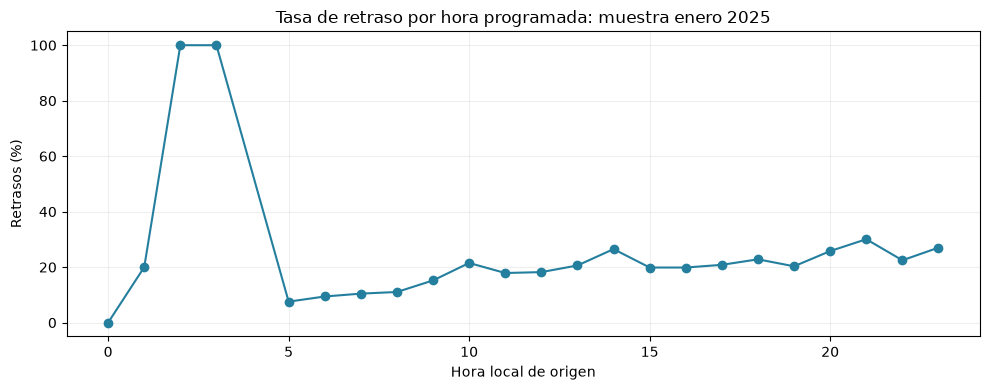

In [5]:
eligible['scheduled_hour']=eligible.CRSDepTime.map(hhmm_minutes).floordiv(60).mod(24).astype('Int64')
by_hour=eligible.groupby('scheduled_hour').agg(vuelos=('delay15','size'),tasa=('delay15','mean'))
by_airline=eligible.groupby('Reporting_Airline').agg(vuelos=('delay15','size'),tasa=('delay15','mean')).sort_values('vuelos',ascending=False)
by_origin=eligible.groupby('Origin').agg(vuelos=('delay15','size'),tasa=('delay15','mean'))
display(by_hour)
display(by_airline)
display(by_origin[by_origin.vuelos.ge(30)].sort_values('tasa',ascending=False).head(15))
fig,ax=plt.subplots()
ax.plot(by_hour.index,by_hour.tasa.mul(100),marker='o',color='#247f9e')
ax.set(title='Tasa de retraso por hora programada: muestra enero 2025',xlabel='Hora local de origen',ylabel='Retrasos (%)')
fig.tight_layout();fig.savefig(figures/'sample_delay_by_hour.png',dpi=160,bbox_inches='tight');plt.show()

Los denominadores son vuelos elegibles de la muestra. El umbral de 30 por aeropuerto es una regla descriptiva para evitar rankings con grupos diminutos, no una prueba de significancia. Las tasas por hora mezclan zonas horarias locales y rutas diferentes; no demuestran causalidad.

## Evidencia histórica guardada de 24 meses

In [6]:
historical=pd.read_csv(ROOT/'reports/tables/antecedentes/monthly_saved_outputs.csv')
display(historical)
print('Suma de vuelos elegibles en salidas guardadas:',historical.eligible_departures.sum())
print('Procedencia: salida guardada de celda 18 del original; no recalculada desde el Parquet histórico.')

,year,month,eligible_departures,delayed_departures,delay_rate_percent_saved
0,2024,1,4837,1158,23.94
1,2024,2,4973,826,16.61
2,2024,3,4952,1005,20.29
3,2024,4,4967,984,19.81
4,2024,5,4933,1255,25.44
5,2024,6,4938,1241,25.13
6,2024,7,4855,1440,29.66
7,2024,8,4907,1177,23.99
8,2024,9,4962,784,15.80
9,2024,10,4945,717,14.50


Suma de vuelos elegibles en salidas guardadas: 118273
Procedencia: salida guardada de celda 18 del original; no recalculada desde el Parquet histórico.


## Hallazgos y preguntas abiertas
- Enero de 2025 tiene 18.53% de retrasos de al menos 15 minutos entre los 4,836 vuelos elegibles de la muestra; no es una estimación del año completo.
- El original conserva una muestra de 5,000 filas por cada uno de 24 meses y 118,273 vuelos elegibles. Muestrear igual por mes produce una mezcla mensual uniforme, no una muestra uniforme de todos los vuelos; para estimaciones poblacionales usar conteos completos o ponderación por mes.
- La correlación mensual guardada entre años es 0.711. Dos años no prueban estacionalidad estable. Mayo-julio es una hipótesis; cualquier selección para predicción se estima exclusivamente con entrenamiento.
- Falta recuperar el Parquet histórico y reproducir las salidas completas; crear el workspace y ejecutar Bronze/Silver/Gold.
- Verificar zonas horarias y disponibilidad real de resultados/publicaciones al corte de tres horas antes de construir tasas históricas o integrar clima.
- Preguntas: ¿cambian las diferencias de aerolíneas al controlar rutas/horarios? ¿qué aeropuertos tienen muestra suficiente? ¿cómo cambian las tasas con volumen completo y validación temporal?

Ver [auditoría del notebook](../docs/notebook_audit.md), [validaciones](../docs/validation.md) y [reparto](../docs/team_workplan.md).